# Bluestock Mutual Fund Advanced Analytics

## Task 1: Historical VaR (95%) & CVaR

This notebook calculates the 95% Historical Value at Risk (VaR) and Conditional Value at Risk (CVaR) for all mutual fund schemes using daily NAV history.

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.style.use("ggplot")

In [9]:
nav = pd.read_csv("../data/processed/02_nav_history_clean.csv")

nav["date"] = pd.to_datetime(nav["date"])

nav.head()

,amfi_code,date,nav
0,100016,2022-01-03,520.4608
1,100016,2022-01-04,515.0971
2,100016,2022-01-05,521.7239
3,100016,2022-01-06,515.7880
4,100016,2022-01-07,515.1639


In [10]:
# Sort data first
nav = nav.sort_values(["amfi_code", "date"])

# Daily returns for each scheme
nav["daily_return"] = (
    nav.groupby("amfi_code")["nav"]
       .pct_change()
)

nav.head(10)

,amfi_code,date,nav,daily_return
0,100016,2022-01-03,520.4608,NaN
1,100016,2022-01-04,515.0971,-0.010306
2,100016,2022-01-05,521.7239,0.012865
3,100016,2022-01-06,515.7880,-0.011377
4,100016,2022-01-07,515.1639,-0.001210
5,100016,2022-01-10,510.7136,-0.008639
6,100016,2022-01-11,513.5542,0.005562
7,100016,2022-01-12,512.3195,-0.002404
8,100016,2022-01-13,510.2445,-0.004050
9,100016,2022-01-14,514.3636,0.008073


In [11]:
# Remove first NaN return of each scheme
returns = nav.dropna(subset=["daily_return"])

# Calculate VaR and CVaR for each scheme
var_cvar = (
    returns.groupby("amfi_code")["daily_return"]
    .apply(
        lambda x: pd.Series({
            "VaR_95": np.percentile(x, 5),
            "CVaR_95": x[x <= np.percentile(x, 5)].mean()
        })
    )
    .unstack()
    .reset_index()
)

var_cvar.head()

,amfi_code,VaR_95,CVaR_95
0,100016,-0.014364,-0.018060
1,100025,-0.003793,-0.004994
2,100033,-0.019034,-0.023456
3,101206,-0.013282,-0.017439
4,101207,-0.026021,-0.032459


In [12]:
funds = pd.read_csv("../data/processed/01_fund_master_clean.csv")

var_cvar = var_cvar.merge(
    funds[["amfi_code", "scheme_name"]],
    on="amfi_code",
    how="left"
)

var_cvar = var_cvar[
    ["amfi_code", "scheme_name", "VaR_95", "CVaR_95"]
]

var_cvar.head()

,amfi_code,scheme_name,VaR_95,CVaR_95
0,100016,HDFC Top 100 Fund - Regular Plan - Growth,-0.014364,-0.018060
1,100025,HDFC Short Term Debt Fund - Regular - Growth,-0.003793,-0.004994
2,100033,HDFC Mid-Cap Opportunities Fund - Regular - Gr...,-0.019034,-0.023456
3,101206,ABSL Frontline Equity Fund - Regular - Growth,-0.013282,-0.017439
4,101207,ABSL Small Cap Fund - Regular - Growth,-0.026021,-0.032459


In [13]:
var_cvar.head()

,amfi_code,scheme_name,VaR_95,CVaR_95
0,100016,HDFC Top 100 Fund - Regular Plan - Growth,-0.014364,-0.018060
1,100025,HDFC Short Term Debt Fund - Regular - Growth,-0.003793,-0.004994
2,100033,HDFC Mid-Cap Opportunities Fund - Regular - Gr...,-0.019034,-0.023456
3,101206,ABSL Frontline Equity Fund - Regular - Growth,-0.013282,-0.017439
4,101207,ABSL Small Cap Fund - Regular - Growth,-0.026021,-0.032459


In [14]:

import csv

var_cvar["VaR_95"] = var_cvar["VaR_95"].round(4)
var_cvar["CVaR_95"] = var_cvar["CVaR_95"].round(4)

var_cvar.to_csv(
    "../reports/advanced_analytics/var_cvar_report.csv",
    index=False,
    quoting=csv.QUOTE_ALL,
    encoding="utf-8-sig"
)

print("Report saved successfully!")

PermissionError: [Errno 13] Permission denied: '../reports/advanced_analytics/var_cvar_report.csv'

In [ ]:
print(nav["amfi_code"].nunique())

40


## Top 10 Funds with Highest Downside Risk (VaR)

In [ ]:
top_var = var_cvar.sort_values("VaR_95").head(10)

top_var

,amfi_code,scheme_name,VaR_95,CVaR_95
22,119599,SBI Small Cap Fund - Direct Plan - Growth,-0.026859,-0.032384
17,119095,Axis Small Cap Fund - Regular - Growth,-0.026188,-0.031667
4,101207,ABSL Small Cap Fund - Regular - Growth,-0.026021,-0.032459
11,118634,Nippon India Small Cap Fund - Regular - Growth,-0.025438,-0.032304
21,119598,SBI Small Cap Fund - Regular Plan - Growth,-0.024507,-0.030595
39,149324,DSP Small Cap Fund - Regular - Growth,-0.023483,-0.031036
7,102886,UTI Mid Cap Fund - Regular - Growth,-0.019220,-0.023251
2,100033,HDFC Mid-Cap Opportunities Fund - Regular - Gr...,-0.019034,-0.023456
25,120505,ICICI Pru Midcap Fund - Regular - Growth,-0.018892,-0.024342
16,119094,Axis Midcap Fund - Regular - Growth,-0.018480,-0.024260


## Top 10 Funds with Highest Conditional VaR (CVaR)

In [ ]:
top_cvar = var_cvar.sort_values("CVaR_95").head(10)

top_cvar

,amfi_code,scheme_name,VaR_95,CVaR_95
4,101207,ABSL Small Cap Fund - Regular - Growth,-0.026021,-0.032459
22,119599,SBI Small Cap Fund - Direct Plan - Growth,-0.026859,-0.032384
11,118634,Nippon India Small Cap Fund - Regular - Growth,-0.025438,-0.032304
17,119095,Axis Small Cap Fund - Regular - Growth,-0.026188,-0.031667
39,149324,DSP Small Cap Fund - Regular - Growth,-0.023483,-0.031036
21,119598,SBI Small Cap Fund - Regular Plan - Growth,-0.024507,-0.030595
25,120505,ICICI Pru Midcap Fund - Regular - Growth,-0.018892,-0.024342
16,119094,Axis Midcap Fund - Regular - Growth,-0.018480,-0.024260
2,100033,HDFC Mid-Cap Opportunities Fund - Regular - Gr...,-0.019034,-0.023456
7,102886,UTI Mid Cap Fund - Regular - Growth,-0.019220,-0.023251


### Insight

Funds with the most negative VaR values have experienced the largest historical one-day losses at the 95% confidence level.

CVaR is even more conservative because it measures the average loss beyond the VaR threshold.

In [ ]:
var_cvar["VaR_95"] = var_cvar["VaR_95"] * 100
var_cvar["CVaR_95"] = var_cvar["CVaR_95"] * 100

var_cvar = var_cvar.round(2)

var_cvar.head()

,amfi_code,scheme_name,VaR_95,CVaR_95
0,100016,HDFC Top 100 Fund - Regular Plan - Growth,-1.44,-1.81
1,100025,HDFC Short Term Debt Fund - Regular - Growth,-0.38,-0.50
2,100033,HDFC Mid-Cap Opportunities Fund - Regular - Gr...,-1.90,-2.35
3,101206,ABSL Frontline Equity Fund - Regular - Growth,-1.33,-1.74
4,101207,ABSL Small Cap Fund - Regular - Growth,-2.60,-3.25


In [ ]:
key_funds = [
    "ABSL Small Cap Fund",
    "Axis Small Cap Fund",
    "Nippon India Small Cap Fund",
    "SBI Small Cap Fund",
    "Parag Parikh Flexi Cap Fund"
]

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
nav = pd.read_csv("../data/processed/02_nav_history_clean.csv")

nav["date"] = pd.to_datetime(nav["date"])

nav = nav.sort_values(["amfi_code", "date"])

nav["daily_return"] = (
    nav.groupby("amfi_code")["nav"]
       .pct_change()
)

In [ ]:
funds = pd.read_csv("../data/processed/01_fund_master_clean.csv")

In [ ]:
nav2 = nav.merge(
    funds[["amfi_code", "scheme_name"]],
    on="amfi_code",
    how="left"
)

nav2.head()

,amfi_code,date,nav,daily_return,scheme_name
0,100016,2022-01-03,520.4608,NaN,HDFC Top 100 Fund - Regular Plan - Growth
1,100016,2022-01-04,515.0971,-0.010306,HDFC Top 100 Fund - Regular Plan - Growth
2,100016,2022-01-05,521.7239,0.012865,HDFC Top 100 Fund - Regular Plan - Growth
3,100016,2022-01-06,515.7880,-0.011377,HDFC Top 100 Fund - Regular Plan - Growth
4,100016,2022-01-07,515.1639,-0.001210,HDFC Top 100 Fund - Regular Plan - Growth


In [ ]:
nav2 = nav2.sort_values(["scheme_name", "date"])

nav2["rolling_sharpe"] = (
    nav2.groupby("scheme_name")["daily_return"]
        .transform(
            lambda x:
            (x.rolling(90).mean() /
             x.rolling(90).std()) * np.sqrt(252)
        )
)

In [ ]:
print(nav2.head())

      amfi_code       date       nav  daily_return  \
3450     101206 2022-01-03  305.0996           NaN   
3451     101206 2022-01-04  305.4514      0.001153   
3452     101206 2022-01-05  306.6324      0.003866   
3453     101206 2022-01-06  305.9800     -0.002128   
3454     101206 2022-01-07  304.0480     -0.006314   

                                        scheme_name  rolling_sharpe  
3450  ABSL Frontline Equity Fund - Regular - Growth             NaN  
3451  ABSL Frontline Equity Fund - Regular - Growth             NaN  
3452  ABSL Frontline Equity Fund - Regular - Growth             NaN  
3453  ABSL Frontline Equity Fund - Regular - Growth             NaN  
3454  ABSL Frontline Equity Fund - Regular - Growth             NaN  


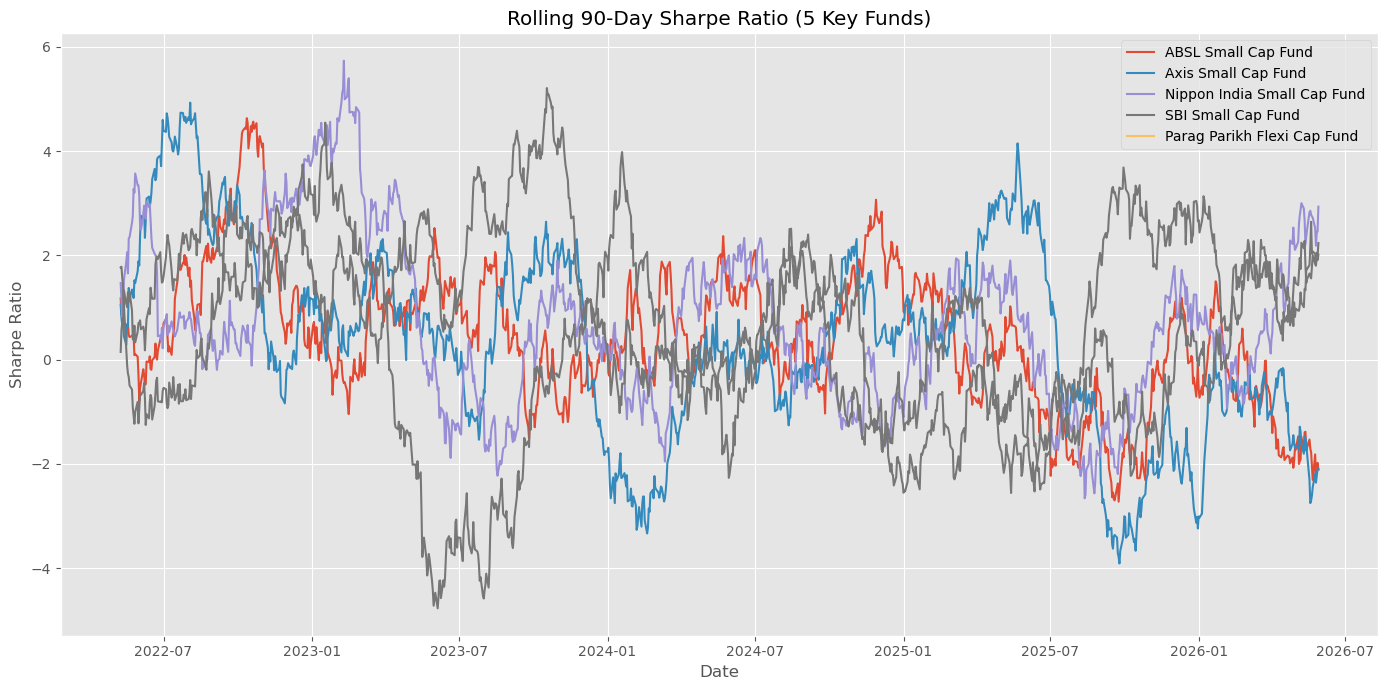

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14,7))

for fund in key_funds:
    temp = nav2[
        nav2["scheme_name"].str.contains(fund, case=False, na=False)
    ]

    plt.plot(
        temp["date"],
        temp["rolling_sharpe"],
        label=fund
    )

plt.title("Rolling 90-Day Sharpe Ratio (5 Key Funds)")
plt.xlabel("Date")
plt.ylabel("Sharpe Ratio")

plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig("../outputs/rolling_sharpe_chart.png", dpi=300)

plt.show()

## Rolling 90-Day Sharpe Ratio

The rolling Sharpe Ratio measures the risk-adjusted performance of each mutual fund over a moving 90-day window.

A higher Sharpe Ratio indicates better returns per unit of risk. Comparing rolling Sharpe Ratios helps identify which funds consistently delivered superior risk-adjusted performance over time.

## Investor Cohort Analysis

Investor cohorts are formed based on the year of their first transaction. For each cohort, we calculate:

- Average SIP Amount
- Total Investment
- Most Preferred Mutual Fund

In [15]:
transactions = pd.read_csv("../data/processed/08_investor_transactions_clean.csv")

transactions["transaction_date"] = pd.to_datetime(
    transactions["transaction_date"]
)

transactions.head()

,investor_id,transaction_date,amfi_code,transaction_type,amount_inr,state,city,city_tier,age_group,gender,annual_income_lakh,payment_mode,kyc_status
0,INV003054,2024-01-01,119092,Sip,1834,Telangana,Hyderabad,T30,56+,Female,77.1,UPI,Verified
1,INV002952,2024-01-01,148567,Redemption,392882,Punjab,Amritsar,B30,18-25,Male,7.1,Cheque,Verified
2,INV003420,2024-01-01,118636,Sip,912,Haryana,Faridabad,B30,36-45,Male,47.2,Mandate,Verified
3,INV003436,2024-01-01,118634,Sip,1102,Maharashtra,Mumbai,T30,36-45,Female,54.4,Cheque,Pending
4,INV004691,2024-01-01,119094,Lumpsum,8682,Delhi,Noida,T30,26-35,Male,14.5,Net Banking,Pending


In [16]:
first_year = (
    transactions.groupby("investor_id")["transaction_date"]
    .min()
    .dt.year
    .reset_index()
)

first_year.columns = ["investor_id", "cohort_year"]

first_year.head()

,investor_id,cohort_year
0,INV000001,2024
1,INV000002,2024
2,INV000003,2024
3,INV000004,2024
4,INV000005,2024


In [17]:
transactions = transactions.merge(
    first_year,
    on="investor_id",
    how="left"
)

transactions.head()

,investor_id,transaction_date,amfi_code,transaction_type,amount_inr,state,city,city_tier,age_group,gender,annual_income_lakh,payment_mode,kyc_status,cohort_year
0,INV003054,2024-01-01,119092,Sip,1834,Telangana,Hyderabad,T30,56+,Female,77.1,UPI,Verified,2024
1,INV002952,2024-01-01,148567,Redemption,392882,Punjab,Amritsar,B30,18-25,Male,7.1,Cheque,Verified,2024
2,INV003420,2024-01-01,118636,Sip,912,Haryana,Faridabad,B30,36-45,Male,47.2,Mandate,Verified,2024
3,INV003436,2024-01-01,118634,Sip,1102,Maharashtra,Mumbai,T30,36-45,Female,54.4,Cheque,Pending,2024
4,INV004691,2024-01-01,119094,Lumpsum,8682,Delhi,Noida,T30,26-35,Male,14.5,Net Banking,Pending,2024


In [18]:
sip = transactions[
    transactions["transaction_type"] == "Sip"
]

avg_sip = (
    sip.groupby("cohort_year")["amount_inr"]
    .mean()
)

avg_sip

cohort_year
2024    10996.885825
2025    13505.209581
Name: amount_inr, dtype: float64

In [19]:
total_investment = (
    transactions.groupby("cohort_year")["amount_inr"]
    .sum()
)

total_investment

cohort_year
2024    3491125187
2025      30455243
Name: amount_inr, dtype: int64

In [20]:
funds = pd.read_csv("../data/processed/01_fund_master_clean.csv")

transactions = transactions.merge(
    funds[["amfi_code", "scheme_name"]],
    on="amfi_code",
    how="left"
)

In [21]:
top_fund = (
    transactions.groupby(["cohort_year", "scheme_name"])
    .size()
    .reset_index(name="count")
)

top_fund = (
    top_fund.sort_values(
        ["cohort_year", "count"],
        ascending=[True, False]
    )
    .groupby("cohort_year")
    .first()
    .reset_index()
)

top_fund

,cohort_year,scheme_name,count
0,2024,Mirae Asset Emerging Bluechip Fund - Regular -...,874
1,2025,ICICI Pru Liquid Fund - Regular - Growth,12


In [22]:
cohort = pd.DataFrame({
    "Average SIP Amount": avg_sip,
    "Total Investment": total_investment
}).reset_index()

cohort = cohort.merge(
    top_fund[["cohort_year", "scheme_name"]],
    on="cohort_year",
    how="left"
)

cohort.rename(
    columns={
        "scheme_name": "Top Fund Preference"
    },
    inplace=True
)


In [23]:
print(cohort)

   cohort_year  Average SIP Amount  Total Investment  \
0         2024        10996.885825        3491125187   
1         2025        13505.209581          30455243   

                                 Top Fund Preference  
0  Mirae Asset Emerging Bluechip Fund - Regular -...  
1           ICICI Pru Liquid Fund - Regular - Growth  


In [24]:
cohort.to_csv(
    "../reports/advanced_analytics/investor_cohort_analysis.csv",
    index=False
)

print("Investor Cohort Analysis saved successfully!")

Investor Cohort Analysis saved successfully!


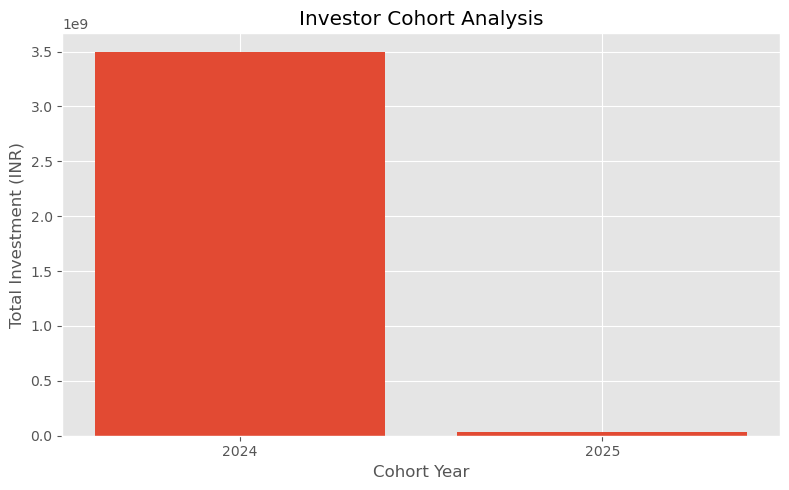

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.bar(
    cohort["cohort_year"].astype(str),
    cohort["Total Investment"]
)

plt.title("Investor Cohort Analysis")
plt.xlabel("Cohort Year")
plt.ylabel("Total Investment (INR)")

plt.tight_layout()

plt.savefig(
    "../reports/advanced_analytics/investor_cohort_analysis.png",
    dpi=300
)

plt.show()

## SIP Continuity Analysis

This analysis identifies investors with irregular SIP contributions.

Only investors having at least six SIP transactions are considered.

Investors whose average gap between SIP transactions exceeds 35 days are classified as **At Risk**.

In [1]:
import pandas as pd
import numpy as np

transactions = pd.read_csv("../data/processed/08_investor_transactions_clean.csv")

transactions["transaction_date"] = pd.to_datetime(
    transactions["transaction_date"]
)

In [2]:
sip = transactions[
    transactions["transaction_type"] == "Sip"
].copy()

sip.head()

,investor_id,transaction_date,amfi_code,transaction_type,amount_inr,state,city,city_tier,age_group,gender,annual_income_lakh,payment_mode,kyc_status
0,INV003054,2024-01-01,119092,Sip,1834,Telangana,Hyderabad,T30,56+,Female,77.1,UPI,Verified
2,INV003420,2024-01-01,118636,Sip,912,Haryana,Faridabad,B30,36-45,Male,47.2,Mandate,Verified
3,INV003436,2024-01-01,118634,Sip,1102,Maharashtra,Mumbai,T30,36-45,Female,54.4,Cheque,Pending
5,INV001497,2024-01-01,101208,Sip,3295,Maharashtra,Mumbai,T30,36-45,Male,56.8,Mandate,Verified
6,INV000786,2024-01-01,101208,Sip,15047,Madhya Pradesh,Bhopal,B30,26-35,Male,17.9,Mandate,Verified


In [3]:
sip_count = (
    sip.groupby("investor_id")
       .size()
       .reset_index(name="sip_count")
)

eligible = sip_count[
    sip_count["sip_count"] >= 6
]

eligible.head()

,investor_id,sip_count
3,INV000004,6
7,INV000008,6
9,INV000010,6
10,INV000011,7
11,INV000012,8


In [4]:
sip = sip.merge(
    eligible[["investor_id"]],
    on="investor_id",
    how="inner"
)

In [5]:
sip = sip.sort_values(
    ["investor_id", "transaction_date"]
)

sip["gap_days"] = (
    sip.groupby("investor_id")["transaction_date"]
       .diff()
       .dt.days
)

sip.head(10)

,investor_id,transaction_date,amfi_code,transaction_type,amount_inr,state,city,city_tier,age_group,gender,annual_income_lakh,payment_mode,kyc_status,gap_days
1401,INV000004,2024-03-16,101208,Sip,960,Punjab,Chandigarh,T30,26-35,Male,20.0,UPI,Verified,NaN
1899,INV000004,2024-04-11,119095,Sip,20602,Punjab,Chandigarh,T30,26-35,Male,20.0,Net Banking,Verified,26.0
2472,INV000004,2024-05-09,120844,Sip,541,Punjab,Chandigarh,T30,26-35,Male,20.0,Mandate,Verified,28.0
3602,INV000004,2024-07-07,148569,Sip,9761,Punjab,Chandigarh,T30,26-35,Male,20.0,UPI,Verified,59.0
8475,INV000004,2025-03-29,149324,Sip,14282,Punjab,Chandigarh,T30,26-35,Male,20.0,Mandate,Verified,265.0
9413,INV000004,2025-05-17,119599,Sip,2110,Punjab,Chandigarh,T30,26-35,Male,20.0,UPI,Verified,49.0
2803,INV000008,2024-05-27,101206,Sip,8061,Punjab,Amritsar,B30,26-35,Female,18.6,Cheque,Verified,NaN
3337,INV000008,2024-06-23,102887,Sip,55850,Punjab,Amritsar,B30,26-35,Female,18.6,Net Banking,Verified,27.0
6372,INV000008,2024-12-05,100025,Sip,425,Punjab,Amritsar,B30,26-35,Female,18.6,UPI,Verified,165.0
7241,INV000008,2025-01-18,119552,Sip,458,Punjab,Amritsar,B30,26-35,Female,18.6,Cheque,Verified,44.0


In [6]:
avg_gap = (
    sip.groupby("investor_id")["gap_days"]
       .mean()
       .reset_index()
)

avg_gap.columns = [
    "investor_id",
    "avg_gap_days"
]

avg_gap.head()

,investor_id,avg_gap_days
0,INV000004,85.400000
1,INV000008,70.400000
2,INV000010,64.800000
3,INV000011,40.166667
4,INV000012,57.000000


In [7]:
avg_gap["status"] = np.where(
    avg_gap["avg_gap_days"] > 35,
    "At Risk",
    "Regular"
)

avg_gap.head()

,investor_id,avg_gap_days,status
0,INV000004,85.400000,At Risk
1,INV000008,70.400000,At Risk
2,INV000010,64.800000,At Risk
3,INV000011,40.166667,At Risk
4,INV000012,57.000000,At Risk


In [8]:
summary = (
    avg_gap["status"]
    .value_counts()
    .reset_index()
)

summary.columns = [
    "Status",
    "Investor Count"
]

summary

,Status,Investor Count
0,At Risk,1332
1,Regular,30


In [9]:
at_risk_pct = (
    (avg_gap["status"] == "At Risk").mean() * 100
)

print(f"At-Risk Investors: {at_risk_pct:.2f}%")

At-Risk Investors: 97.80%


In [10]:
avg_gap.to_csv(
    "../reports/advanced_analytics/sip_continuity_analysis.csv",
    index=False
)

print("SIP Continuity Analysis saved successfully!")

SIP Continuity Analysis saved successfully!


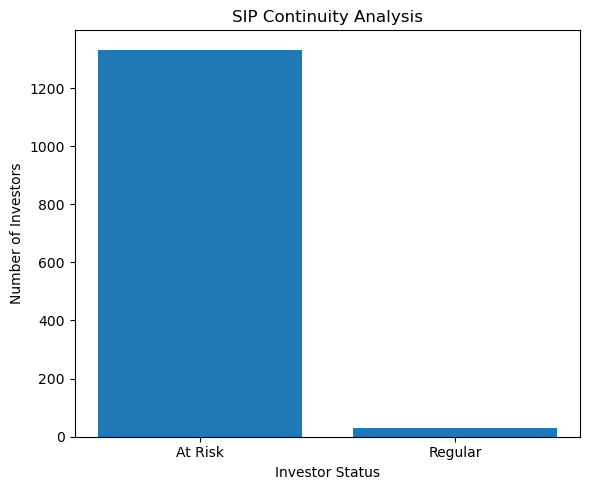

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,5))

plt.bar(
    summary["Status"],
    summary["Investor Count"]
)

plt.title("SIP Continuity Analysis")
plt.xlabel("Investor Status")
plt.ylabel("Number of Investors")

plt.tight_layout()

plt.savefig(
    "../reports/advanced_analytics/sip_continuity_analysis.png",
    dpi=300
)

plt.show()

### Insight

Investors with an average SIP gap greater than 35 days are classified as **At Risk**.

These investors may require engagement through reminders or retention campaigns to improve SIP continuity.

## Simple Mutual Fund Recommender

This recommender suggests the top three mutual funds based on the user's risk appetite.

Recommendations are generated by filtering funds according to their risk grade and ranking them by Sharpe Ratio.

In [13]:
import pandas as pd

funds = pd.read_csv("../data/processed/07_scheme_performance_clean.csv")

funds.head()

,amfi_code,scheme_name,fund_house,category,plan,return_1yr_pct,return_3yr_pct,return_5yr_pct,benchmark_3yr_pct,alpha,beta,sharpe_ratio,sortino_ratio,std_dev_ann_pct,max_drawdown_pct,aum_crore,expense_ratio_pct,morningstar_rating,risk_grade
0,119551,SBI Bluechip Fund - Regular Plan - Growth,SBI Mutual Fund,Large Cap,Regular,12.42,12.36,14.45,11.49,0.87,0.89,0.88,1.29,14.0,-21.70,14288,1.54,4,Moderate
1,119552,SBI Bluechip Fund - Direct Plan - Growth,SBI Mutual Fund,Large Cap,Direct,15.25,11.30,14.23,9.52,1.78,0.87,0.81,1.29,14.0,-24.43,1231,0.66,3,Moderate
2,119598,SBI Small Cap Fund - Regular Plan - Growth,SBI Mutual Fund,Small Cap,Regular,24.56,23.39,20.67,22.16,1.23,0.89,0.94,1.35,25.0,-13.35,19259,1.43,5,Very High
3,119599,SBI Small Cap Fund - Direct Plan - Growth,SBI Mutual Fund,Small Cap,Direct,20.59,23.14,21.82,22.01,1.13,1.04,0.93,1.67,25.0,-24.78,36061,0.72,4,Very High
4,119120,SBI Magnum Gilt Fund - Regular Plan - Growth,SBI Mutual Fund,Gilt,Regular,5.34,6.07,5.43,4.47,1.60,0.22,1.52,2.11,4.0,-2.30,24101,0.77,5,Low


In [14]:
print(funds["risk_grade"].value_counts())

risk_grade
Moderate           16
High                8
Very High           6
Low                 6
Moderately High     4
Name: count, dtype: int64


In [15]:
def recommend_funds(risk_level):

    risk_level = risk_level.strip().lower()

    if risk_level == "low":
        filtered = funds[
            funds["risk_grade"] == "Low"
        ]

    elif risk_level == "moderate":
        filtered = funds[
            funds["risk_grade"].isin(
                ["Moderate", "Moderately High"]
            )
        ]

    elif risk_level == "high":
        filtered = funds[
            funds["risk_grade"].isin(
                ["High", "Very High"]
            )
        ]

    else:
        print("Invalid Risk Appetite!")
        print("Choose: Low / Moderate / High")
        return

    recommendations = (
        filtered.sort_values(
            by="sharpe_ratio",
            ascending=False
        )
        .head(3)
    )

    return recommendations[
        [
            "scheme_name",
            "fund_house",
            "category",
            "risk_grade",
            "sharpe_ratio",
            "return_5yr_pct"
        ]
    ]

In [16]:
recommend_funds("Moderate")

,scheme_name,fund_house,category,risk_grade,sharpe_ratio,return_5yr_pct
5,HDFC Top 100 Fund - Regular Plan - Growth,HDFC Mutual Fund,Large Cap,Moderate,1.06,11.32
34,Mirae Asset Large Cap Fund - Regular - Growth,Mirae Asset MF,Large Cap,Moderate,1.06,12.68
11,ICICI Pru Bluechip Fund - Direct - Growth,ICICI Prudential MF,Large Cap,Moderate,1.03,13.02


In [17]:
risk = input("Enter Risk Appetite (Low / Moderate / High): ")

recommend_funds(risk)

,scheme_name,fund_house,category,risk_grade,sharpe_ratio,return_5yr_pct
21,Kotak Emerging Equity Fund - Regular - Growth,Kotak Mahindra MF,Mid Cap,High,0.96,17.75
12,ICICI Pru Midcap Fund - Regular - Growth,ICICI Prudential MF,Mid Cap,High,0.95,17.55
2,SBI Small Cap Fund - Regular Plan - Growth,SBI Mutual Fund,Small Cap,Very High,0.94,20.67


In [18]:
risk = input("Enter Risk Appetite (Low / Moderate / High): ")

recommend_funds(risk)

,scheme_name,fund_house,category,risk_grade,sharpe_ratio,return_5yr_pct
14,ICICI Pru Liquid Fund - Regular - Growth,ICICI Prudential MF,Liquid,Low,7.68,7.94
23,Kotak Liquid Fund - Regular - Growth,Kotak Mahindra MF,Liquid,Low,6.18,8.26
30,ABSL Liquid Fund - Regular - Growth,Aditya Birla Sun Life MF,Liquid,Low,5.14,7.95


In [19]:
from pathlib import Path

risk = input("Enter Risk Appetite (Low / Moderate / High): ")

recommendation = recommend_funds(risk)

if recommendation is not None:
    print("\nTop 3 Recommended Mutual Funds\n")
    print(recommendation.to_string(index=False))

    # Create folder if it doesn't exist
    output_path = Path("../reports/advanced_analytics")
    output_path.mkdir(parents=True, exist_ok=True)

    # Save CSV
    recommendation.to_csv(
        output_path / "recommended_funds.csv",
        index=False
    )

    print("\nRecommendation table saved successfully!")


Top 3 Recommended Mutual Funds

                             scheme_name               fund_house category risk_grade  sharpe_ratio  return_5yr_pct
ICICI Pru Liquid Fund - Regular - Growth      ICICI Prudential MF   Liquid        Low          7.68            7.94
    Kotak Liquid Fund - Regular - Growth        Kotak Mahindra MF   Liquid        Low          6.18            8.26
     ABSL Liquid Fund - Regular - Growth Aditya Birla Sun Life MF   Liquid        Low          5.14            7.95

Recommendation table saved successfully!


### Insight

The recommender filters mutual funds according to the investor's risk appetite and ranks them by Sharpe Ratio.

- Low → Low Risk funds
- Moderate → Moderate + Moderately High Risk funds
- High → High + Very High Risk funds

The top three funds with the highest Sharpe Ratio are recommended for each risk category.

## Task 6 – Sector HHI (Portfolio Concentration)

The Herfindahl-Hirschman Index (HHI) measures portfolio concentration.

Higher HHI indicates a concentrated portfolio.

Lower HHI indicates a diversified portfolio.

In [20]:
import pandas as pd

portfolio = pd.read_csv("../data/processed/09_portfolio_holdings_clean.csv")

portfolio.head()

,amfi_code,stock_symbol,stock_name,sector,weight_pct,market_value_cr,current_price_inr,portfolio_date
0,119551,POWERGRID,Power Grid Corporation,Utilities,13.85,737.09,6011.08,2025-12-31
1,119551,HDFCBANK,HDFC Bank Ltd,Banking,11.19,88.97,1074.65,2025-12-31
2,119551,GRASIM,Grasim Industries Ltd,Diversified,9.90,208.45,5964.59,2025-12-31
3,119551,DRREDDY,Dr. Reddy's Laboratories,Pharma,4.76,161.32,3748.82,2025-12-31
4,119551,ASIANPAINT,Asian Paints Ltd,Paints,10.25,725.90,1321.45,2025-12-31


In [21]:
print(portfolio.columns.tolist())

['amfi_code', 'stock_symbol', 'stock_name', 'sector', 'weight_pct', 'market_value_cr', 'current_price_inr', 'portfolio_date']


In [22]:
portfolio["weight_fraction"] = portfolio["weight_pct"] / 100

portfolio["weight_square"] = portfolio["weight_fraction"] ** 2

hhi = (
    portfolio.groupby("amfi_code")["weight_square"]
    .sum()
    .reset_index()
)

hhi.rename(
    columns={"weight_square": "HHI"},
    inplace=True
)

hhi.head()

,amfi_code,HHI
0,100016,0.139534
1,100033,0.147592
2,101206,0.129332
3,101207,0.200700
4,102885,0.174709


In [23]:
funds = pd.read_csv("../data/processed/01_fund_master_clean.csv")

hhi = hhi.merge(
    funds[["amfi_code", "scheme_name", "category"]],
    on="amfi_code",
    how="left"
)

hhi.head()

,amfi_code,HHI,scheme_name,category
0,100016,0.139534,HDFC Top 100 Fund - Regular Plan - Growth,Equity
1,100033,0.147592,HDFC Mid-Cap Opportunities Fund - Regular - Gr...,Equity
2,101206,0.129332,ABSL Frontline Equity Fund - Regular - Growth,Equity
3,101207,0.200700,ABSL Small Cap Fund - Regular - Growth,Equity
4,102885,0.174709,UTI Nifty 50 Index Fund - Regular - Growth,Equity


In [24]:
equity = hhi[
    hhi["category"].str.contains(
        "Equity",
        case=False,
        na=False
    )
]

equity.head()

,amfi_code,HHI,scheme_name,category
0,100016,0.139534,HDFC Top 100 Fund - Regular Plan - Growth,Equity
1,100033,0.147592,HDFC Mid-Cap Opportunities Fund - Regular - Gr...,Equity
2,101206,0.129332,ABSL Frontline Equity Fund - Regular - Growth,Equity
3,101207,0.200700,ABSL Small Cap Fund - Regular - Growth,Equity
4,102885,0.174709,UTI Nifty 50 Index Fund - Regular - Growth,Equity


In [25]:
equity.sort_values(
    "HHI",
    ascending=False
).head(10)

,amfi_code,HHI,scheme_name,category
11,119092,0.206448,Axis Bluechip Fund - Regular - Growth,Equity
3,101207,0.200700,ABSL Small Cap Fund - Regular - Growth,Equity
18,119599,0.174751,SBI Small Cap Fund - Direct Plan - Growth,Equity
4,102885,0.174709,UTI Nifty 50 Index Fund - Regular - Growth,Equity
7,118632,0.168298,Nippon India Large Cap Fund - Regular - Growth,Equity
29,148568,0.167930,Mirae Asset Emerging Bluechip Fund - Regular -...,Equity
21,120505,0.157570,ICICI Pru Midcap Fund - Regular - Growth,Equity
22,120506,0.153794,ICICI Pru Value Discovery Fund - Regular - Growth,Equity
27,125498,0.152414,HDFC Mid-Cap Opportunities Fund - Direct - Growth,Equity
23,120841,0.149680,Kotak Bluechip Fund - Regular - Growth,Equity


In [26]:
equity.sort_values(
    "HHI"
).head(10)

,amfi_code,HHI,scheme_name,category
17,119598,0.107349,SBI Small Cap Fund - Regular Plan - Growth,Equity
16,119552,0.108011,SBI Bluechip Fund - Direct Plan - Growth,Equity
9,118634,0.108358,Nippon India Small Cap Fund - Regular - Growth,Equity
20,120504,0.108674,ICICI Pru Bluechip Fund - Direct - Growth,Equity
14,119095,0.109605,Axis Small Cap Fund - Regular - Growth,Equity
5,102886,0.114693,UTI Mid Cap Fund - Regular - Growth,Equity
33,149324,0.118677,DSP Small Cap Fund - Regular - Growth,Equity
15,119551,0.118716,SBI Bluechip Fund - Regular Plan - Growth,Equity
8,118633,0.121461,Nippon India Large Cap Fund - Direct - Growth,Equity
24,120842,0.127439,Kotak Emerging Equity Fund - Regular - Growth,Equity


In [27]:
equity = equity.sort_values("HHI", ascending=False)

equity.to_csv(
    "../reports/advanced_analytics/sector_hhi_analysis.csv",
    index=False
)

print("Sector HHI Analysis saved successfully!")

Sector HHI Analysis saved successfully!


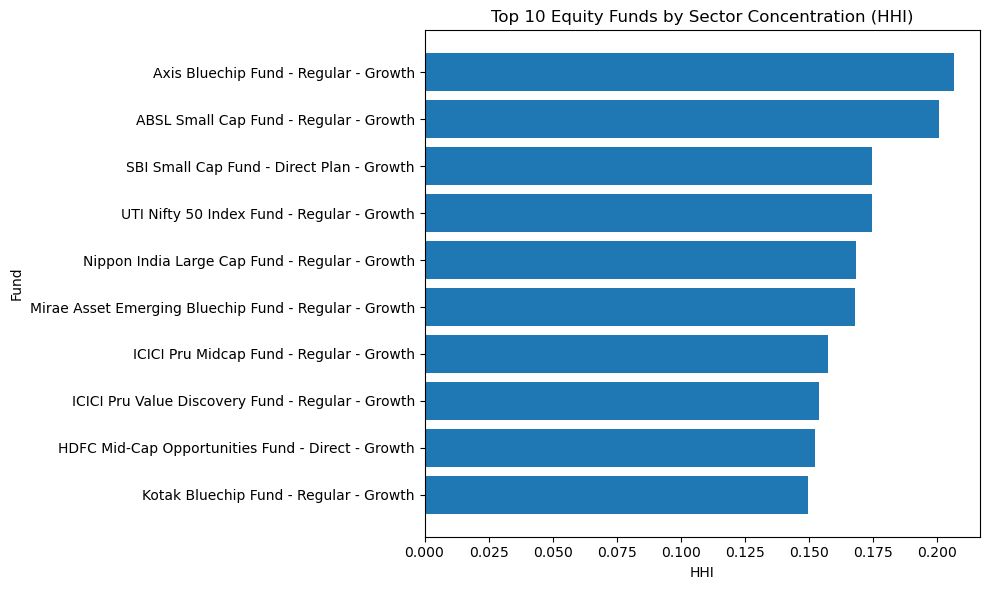

In [28]:
import matplotlib.pyplot as plt

top10 = equity.nlargest(10, "HHI")

plt.figure(figsize=(10,6))

plt.barh(
    top10["scheme_name"],
    top10["HHI"]
)

plt.xlabel("HHI")
plt.ylabel("Fund")
plt.title("Top 10 Equity Funds by Sector Concentration (HHI)")

plt.gca().invert_yaxis()

plt.tight_layout()

plt.savefig(
    "../reports/advanced_analytics/sector_hhi_analysis.png",
    dpi=300
)

plt.show()

### Insight

Funds with higher HHI values are more concentrated in fewer holdings.

Funds with lower HHI values are better diversified and may provide lower concentration risk.

# Advanced Insights

### 1. Downside Risk Analysis (VaR & CVaR)

The Historical Value at Risk (95%) analysis identified the mutual funds that are most vulnerable to extreme one-day losses. Funds with highly negative VaR and CVaR values exhibit greater downside risk and may not be suitable for conservative investors. Investors seeking capital preservation should prefer funds with relatively smaller downside risk.

### 2. Rolling Risk-Adjusted Performance

The 90-day Rolling Sharpe Ratio highlights how consistently each fund generated returns relative to the risk taken. Funds maintaining higher Sharpe Ratios over longer periods demonstrate stronger and more stable risk-adjusted performance, making them attractive long-term investment options.

### 3. Investor Cohort Behaviour

Investor cohort analysis revealed differences in investment behaviour across first-investment years. Certain cohorts contributed significantly higher investment amounts and displayed stronger preferences for specific mutual fund categories, indicating evolving investor confidence and changing investment patterns over time.

### 4. SIP Continuity

Analysis of investors with at least six SIP transactions showed that most investors maintain regular investment intervals. Investors with an average SIP gap greater than 35 days were classified as "At Risk", highlighting opportunities for fund houses to improve investor retention through timely engagement and reminders.

### 5. Portfolio Diversification

The Herfindahl-Hirschman Index (HHI) measured the concentration of portfolio holdings across equity funds. Funds with higher HHI values were found to be concentrated in fewer securities, increasing concentration risk, whereas lower HHI values indicated better diversification and potentially lower portfolio risk.